In [ ]:
# from utils import *
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, f1_score, mean_squared_error, make_scorer, confusion_matrix, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import seaborn as sns

from tensorflow import keras
from tensorflow.keras.layers import Bidirectional, Dropout, Activation, Dense, LSTM
from tensorflow.compat.v1.keras.layers import CuDNNLSTM
from tensorflow.keras.models import Sequential

In [ ]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

In [ ]:
raw_data = pd.read_csv("residential_solar_installations_panel_data_contiguous_US.csv", index_col=0)
print(raw_data.shape)
raw_data.columns

(216843, 24)


Index(['cumulative num of residential PVs by 2005',
       'cumulative num of residential PVs by 2006',
       'cumulative num of residential PVs by 2007',
       'cumulative num of residential PVs by 2008',
       'cumulative num of residential PVs by 2009',
       'cumulative num of residential PVs by 2010',
       'cumulative num of residential PVs by 2011',
       'cumulative num of residential PVs by 2012',
       'cumulative num of residential PVs by 2013',
       'cumulative num of residential PVs by 2014',
       'cumulative num of residential PVs by 2015',
       'cumulative num of residential PVs by 2016',
       'cumulative num of residential PVs by 2017', 'number of buildings',
       'number of buildings with footprint < 600m^2', 'avg GHI (W/m^2)',
       'ACS: number of households (2016)',
       'ACS: housing unit density (/mile^2, 2016)',
       'ACS: median household income (inflation adjusted $ in 2016, 2016)',
       'ACS: % housing units occupied (2016)',
       'AC

In [ ]:
features = ['cumulative num of residential PVs by 2005',
       'cumulative num of residential PVs by 2006',
       'cumulative num of residential PVs by 2007',
       'cumulative num of residential PVs by 2008',
       'cumulative num of residential PVs by 2009',
       'cumulative num of residential PVs by 2010',
       'cumulative num of residential PVs by 2011',
       'cumulative num of residential PVs by 2012',
       'cumulative num of residential PVs by 2013',
       'cumulative num of residential PVs by 2014',
       'cumulative num of residential PVs by 2015',
       'cumulative num of residential PVs by 2016',
       'cumulative num of residential PVs by 2017']

columns = features + ['number of buildings']
raw_data = raw_data.dropna(axis=0, how='any', subset=columns) #drop all the rows that have any missing values in the columns we care about
raw_data = raw_data[raw_data['number of buildings']>0] #only keep rows with at least some buildings in them
raw_data = raw_data[raw_data['cumulative num of residential PVs by 2017']>0] #only keep rows with at least one PV in 2017

raw_data = raw_data[features]
raw_data = raw_data.sample(frac = 1)
raw_data = raw_data.reset_index(drop=True)

raw_data.head()

,cumulative num of residential PVs by 2005,cumulative num of residential PVs by 2006,cumulative num of residential PVs by 2007,cumulative num of residential PVs by 2008,cumulative num of residential PVs by 2009,cumulative num of residential PVs by 2010,cumulative num of residential PVs by 2011,cumulative num of residential PVs by 2012,cumulative num of residential PVs by 2013,cumulative num of residential PVs by 2014,cumulative num of residential PVs by 2015,cumulative num of residential PVs by 2016,cumulative num of residential PVs by 2017
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0
1,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,3.0
3,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
4,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,1.0,2.0,2.0,2.0,2.0


In [ ]:
raw_data = raw_data.rename(columns={'cumulative num of residential PVs by 2005': '2005',
       'cumulative num of residential PVs by 2006': 'y2006',
       'cumulative num of residential PVs by 2007': 'y2007',
       'cumulative num of residential PVs by 2008': 'y2008',
       'cumulative num of residential PVs by 2009': 'y2009',
       'cumulative num of residential PVs by 2010': 'y2010',
       'cumulative num of residential PVs by 2011': 'y2011',
       'cumulative num of residential PVs by 2012': 'y2012',
       'cumulative num of residential PVs by 2013': 'y2013',
       'cumulative num of residential PVs by 2014': 'y2014',
       'cumulative num of residential PVs by 2015': 'y2015',
       'cumulative num of residential PVs by 2016': 'y2016',
       'cumulative num of residential PVs by 2017': 'y2017'})

In [ ]:
seq_len = raw_data.shape[1]

def get_train_test_sets(data, seq_len, train_frac):
    n_train = int(data.shape[0] * train_frac)
    
    X_train = data[:n_train].drop(["y2017"], axis=1)
    X_train = np.array(X_train)

    y_train = data.y2017[:n_train]
    
    X_test = data[n_train:].drop(["y2017"], axis=1)
    X_test = np.array(X_test)

    y_test = data.y2017[n_train:]

    return X_train, y_train, X_test, y_test

x_train, y_train, x_test, y_test = get_train_test_sets(raw_data, seq_len, train_frac=0.9)

In [ ]:
from sklearn.preprocessing import MinMaxScaler


X_scaler = StandardScaler().fit(x_train)
x_train = X_scaler.transform(x_train)
x_test = X_scaler.transform(x_test)

y_scaler = StandardScaler().fit(np.array(y_train).reshape(-1,1))
y_train = y_scaler.transform(np.array(y_train).reshape(-1,1))
y_test = y_scaler.transform(np.array(y_test).reshape(-1,1))

In [ ]:
x_train = x_train.reshape(x_train.shape[0],x_train.shape[1] , 1)
x_test = x_test.reshape(x_test.shape[0],x_test.shape[1] , 1)

In [ ]:
x_train.shape

(71750, 12, 1)

In [ ]:
y_train.shape

(71750, 1)

In [ ]:
x_test.shape

(7973, 12, 1)

In [ ]:
# fraction of the input to drop; helps prevent overfitting
dropout = 0.05
window_size = seq_len - 1

# build a 3-layer LSTM RNN
model = keras.Sequential()

model.add(
    LSTM(window_size, return_sequences=True, 
         input_shape=(window_size, x_train.shape[-1]))
)

# model.add(Dropout(rate=dropout))
# # Bidirectional allows for training of sequence data forwards and backwards
# model.add(
#     Bidirectional(LSTM((window_size * 2), return_sequences=True)
# )) 

model.add(Dropout(rate=dropout))
model.add(
    Bidirectional(LSTM(window_size, return_sequences=False))
) 

model.add(Dense(units=1))
# linear activation function: activation is proportional to the input
model.add(Activation('linear'))

In [ ]:
batch_size = 64
optimizer = keras.optimizers.Adam(lr=0.001)

model.compile(
    loss='mean_squared_error',
    optimizer=optimizer,
    metrics=["mae"],

)

history = model.fit(
    x_train,
    y_train,
    epochs=50,
    batch_size=batch_size,
    shuffle=False,
    validation_split=0.2
)

Epoch 1/50
897/897 [==============================] - 33s 27ms/step - loss: 0.2272 - mae: 0.1428 - val_loss: 0.0510 - val_mae: 0.0799
Epoch 2/50
897/897 [==============================] - 16s 18ms/step - loss: 0.0728 - mae: 0.0800 - val_loss: 0.0340 - val_mae: 0.0731
Epoch 3/50
897/897 [==============================] - 16s 17ms/step - loss: 0.0496 - mae: 0.0673 - val_loss: 0.0271 - val_mae: 0.0844
Epoch 4/50
897/897 [==============================] - 18s 20ms/step - loss: 0.0387 - mae: 0.0613 - val_loss: 0.0238 - val_mae: 0.0673
Epoch 5/50
897/897 [==============================] - 16s 17ms/step - loss: 0.0352 - mae: 0.0573 - val_loss: 0.0227 - val_mae: 0.0519
Epoch 6/50
897/897 [==============================] - 17s 18ms/step - loss: 0.0305 - mae: 0.0550 - val_loss: 0.0169 - val_mae: 0.0523
Epoch 7/50
897/897 [==============================] - 18s 20ms/step - loss: 0.0265 - mae: 0.0542 - val_loss: 0.0193 - val_mae: 0.0671
Epoch 8/50
897/897 [==============================] - 16s 18ms

In [ ]:

# Evaluate the model on the test data using `evaluate`
print("Evaluate on test data")
results = model.evaluate(x_test, y_test, batch_size=64)
results

Evaluate on test data
125/125 [==============================] - 1s 9ms/step - loss: 0.0108 - mae: 0.0417


[0.010821664705872536, 0.04166242852807045]

In [ ]:
from sklearn.metrics import r2_score
# Assuming your RNN model is called `model` and your test data is in `X_test` and `y_test`
y_pred = model.predict(x_test)
r2 = r2_score(y_test, y_pred)

print('R2 score:', r2)

250/250 [==============================] - 6s 7ms/step
R2 score: 0.9898349863370114


In [ ]:
print(history.history.keys())

dict_keys(['loss', 'mae', 'val_loss', 'val_mae'])


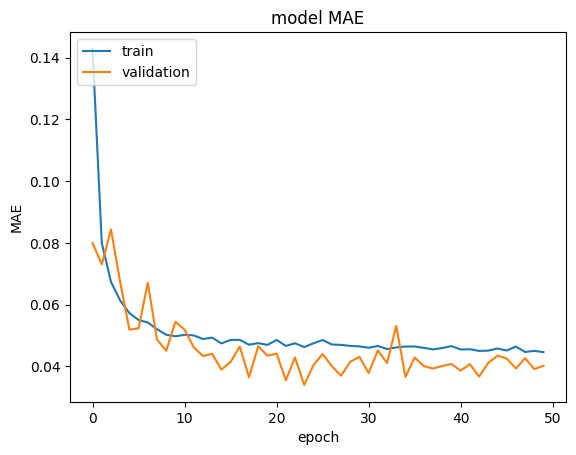

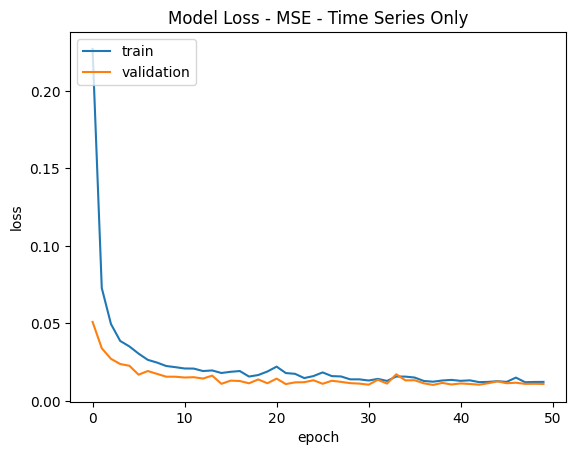

In [ ]:
# summarize history for accuracy
plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])
plt.title('model MAE')
plt.ylabel('MAE')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()
# summarize history for loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss - MSE - Time Series Only')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'validation'], loc='upper left')
plt.show()